## Diving into Amazon UK Product Insights

**Objective**: Explore product listing dynamics on Amazon UK (categories, prices, ratings) to derive insights for product positioning, pricing and inventory decisions.

In [1]:
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
pd.set_option('display.max_columns', None)

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [2]:
df.shape

(2443651, 9)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

### Part 1: Understanding Product Categories

#### 1. Frequency Tables

In [5]:
frequency_table = df.category.value_counts()
proportion_table = df.category.value_counts(normalize=True)

# merging absolute frequency with relative frequencies
df2 = pd.concat([frequency_table, proportion_table], axis=1)
df2.columns = ['absolute_frequency', 'relative_frequency']
df2 = df2.sort_values(by='absolute_frequency', ascending=False)
df2

,absolute_frequency,relative_frequency
category,,
Sports & Outdoors,836265,0.342219
Beauty,19312,0.007903
"Handmade Clothing, Shoes & Accessories",19229,0.007869
Bath & Body,19092,0.007813
Birthday Gifts,18978,0.007766
...,...,...
Alexa Built-In Devices,107,0.000044
Motorbike Chassis,107,0.000044
Plugs,107,0.000044


In [6]:
total_absolute = int(frequency_table.sum())
total_relative = float(proportion_table.sum())

total_row = pd.DataFrame({
    'absolute_frequency': [total_absolute],
    'relative_frequency': [total_relative]
}, index=['Total'])

df3 = pd.concat([df2, total_row])
df3

,absolute_frequency,relative_frequency
Sports & Outdoors,836265,0.342219
Beauty,19312,0.007903
"Handmade Clothing, Shoes & Accessories",19229,0.007869
Bath & Body,19092,0.007813
Birthday Gifts,18978,0.007766
...,...,...
Motorbike Chassis,107,0.000044
Plugs,107,0.000044
Smart Home Security & Lighting,104,0.000043
Smart Speakers,54,0.000022


In [7]:
len(df.category.unique())

296

There are almost 300 different categories. The top 5 most listed categories are:

In [8]:
df2.head(5)

,absolute_frequency,relative_frequency
category,,
Sports & Outdoors,836265,0.342219
Beauty,19312,0.007903
"Handmade Clothing, Shoes & Accessories",19229,0.007869
Bath & Body,19092,0.007813
Birthday Gifts,18978,0.007766


#### 2. Visualizations

A bar chart with almost 300 categories is unreadable, so we only plot the top 20 categories.

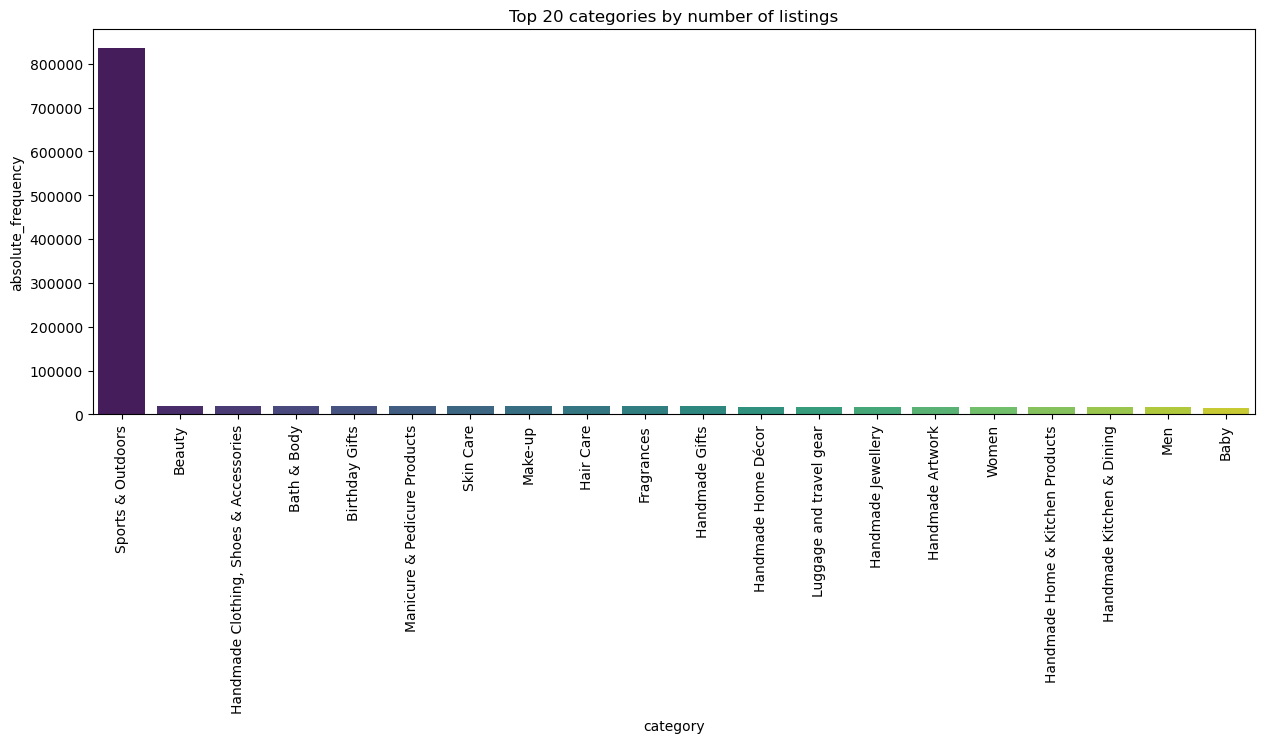

In [9]:
top20 = df2.head(20).reset_index()

fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
sns.barplot(
    x='category',
    y='absolute_frequency',
    data=top20,
    palette='viridis',
    ax=axs
)
axs.set_title('Top 20 categories by number of listings')
plt.xticks(rotation=90)
plt.show()

`Sports & Outdoors` is so large that the other bars are hard to compare. Let's plot the categories ranked 2 to 21 without it:

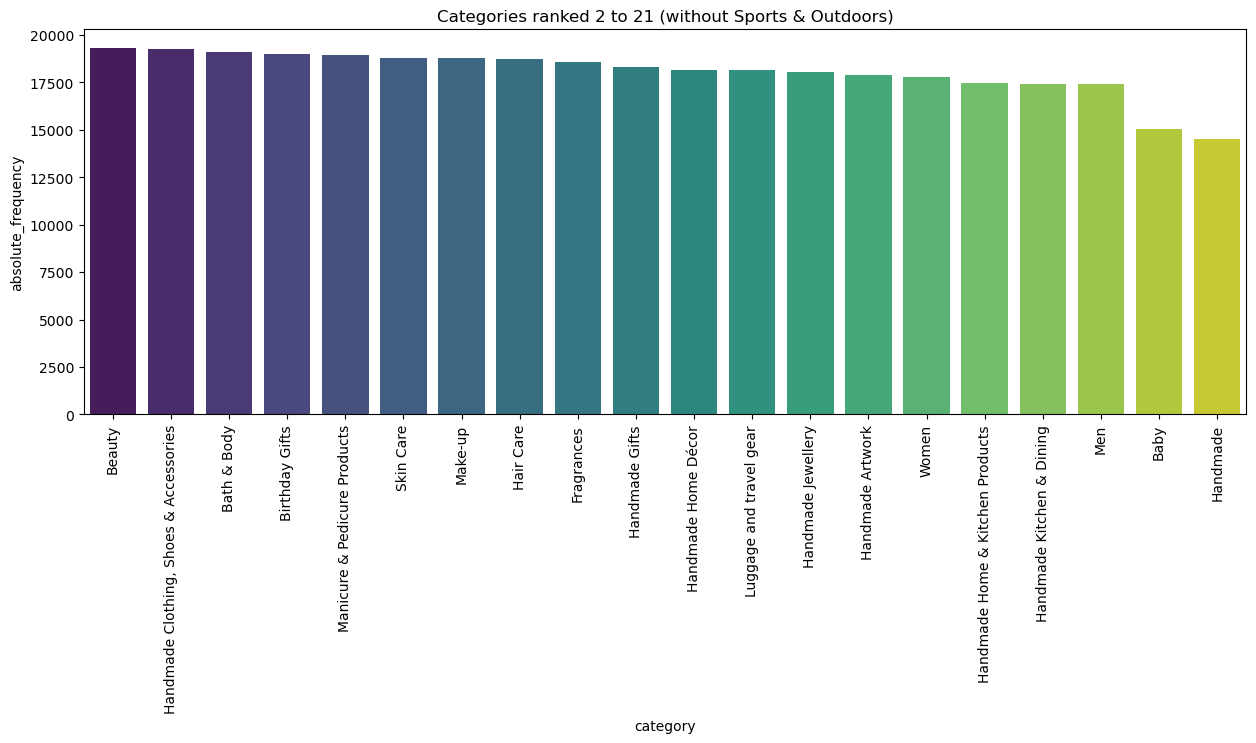

In [10]:
rest = df2.iloc[1:21].reset_index()

fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
sns.barplot(
    x='category',
    y='absolute_frequency',
    data=rest,
    palette='viridis',
    ax=axs
)
axs.set_title('Categories ranked 2 to 21 (without Sports & Outdoors)')
plt.xticks(rotation=90)
plt.show()

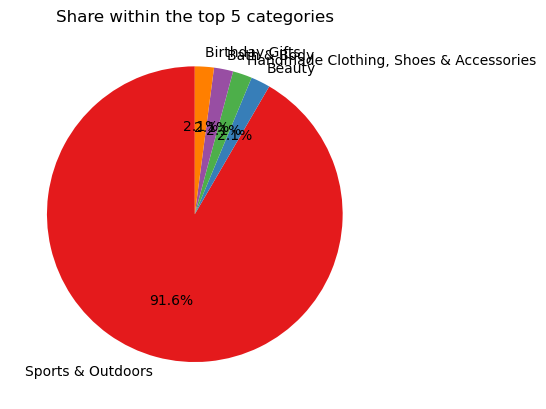

In [11]:
frequency_table.head(5).plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set1'))
plt.title('Share within the top 5 categories')
plt.ylabel('')
plt.show()

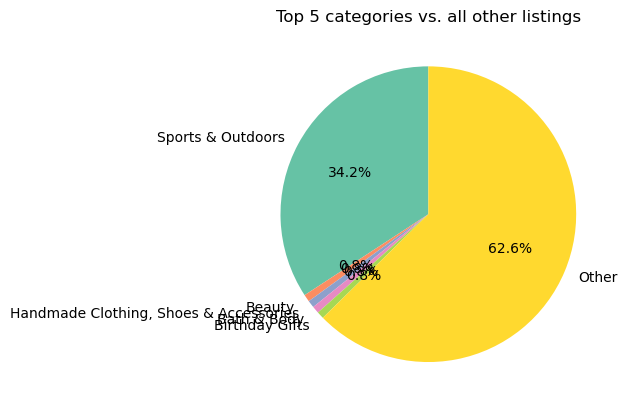

In [12]:
# share of the top 5 categories compared to all other listings
top5_vs_rest = pd.concat([frequency_table.head(5), pd.Series({'Other': frequency_table.iloc[5:].sum()})])

top5_vs_rest.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2'))
plt.title('Top 5 categories vs. all other listings')
plt.ylabel('')
plt.show()

**Insights**

- The top 5 categories are `Sports & Outdoors` (836,265 listings), `Beauty` (19,312), `Handmade Clothing, Shoes & Accessories` (19,229), `Bath & Body` (19,092) and `Birthday Gifts` (18,978).
- `Sports & Outdoors` clearly dominates: it alone makes up **~34% of all listings** and ~91% of the listings within the top 5. Every other category has less than 1% of the listings.
- Below the top category the distribution is very flat: the categories ranked 2 to 10 all have roughly 18,500-19,300 listings. This looks like the data was collected with a similar number of products per category, so listing counts should not be read as true market size.

### Part 2: Delving into Product Pricing

#### 1. Measures of Centrality

In [13]:
round(float(df['price'].mean()), 2)

89.24

In [14]:
round(float(df['price'].median()), 2)

19.09

In [15]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

The mean (~£89) is by a margin higher than the median (~£19) and the mode (£9.99). This means that a few very expensive products push the average up, while most products are in the lower price section. The most common price point is £9.99 - a typical price just below £10.

#### 2. Measures of Dispersion

In [16]:
round(float(df['price'].var()), 2)

119445.49

In [17]:
round(float(df['price'].std()), 2)

345.61

In [18]:
price_min = df['price'].min()
price_max = df['price'].max()
price_range = price_max - price_min
print(f"Min: {price_min}, Max: {price_max}, Range: {price_range}")

Min: 0.0, Max: 100000.0, Range: 100000.0


In [19]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
print(f"Q1: {Q1}, Q3: {Q3}, IQR: {round(IQR, 2)}")

Q1: 9.99, Q3: 45.99, IQR: 36.0


In [20]:
round(df['price'].describe(), 2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

The prices are very widely spread: the range is £100,000 and the standard deviation (~£346) is almost 4 times the mean. At the same time the IQR is only £36 - the middle 50% of products cost between ~£10 and ~£46. So most products are cheap and similar in price, and the huge variance comes from a few very expensive items.

#### 3. Visualizations

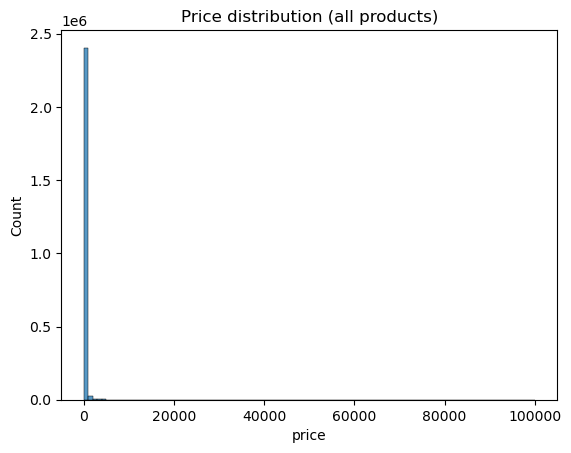

In [21]:
sns.histplot(df['price'], bins=100)
plt.title('Price distribution (all products)')
plt.show()

This histogram is hard to read: the extreme values (up to £100,000) stretch the x-axis so far that almost all products end up in the first bar and the outliers are barely visible. Playing with the bin size makes no big difference.

This can be solved by removing the outliers before plotting. We use Tukey's method: values above `Q3 + 1.5 * IQR` (or below `Q1 - 1.5 * IQR`) are outliers.

In [22]:
def outlier_slayer(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

price_outliers = outlier_slayer(df['price'])
print(f"Number of outliers: {len(price_outliers)} ({round(len(price_outliers) / len(df) * 100, 1)}% of products)")
print(f"Upper bound: {round(Q3 + 1.5 * IQR, 2)}")

Number of outliers: 327688 (13.4% of products)
Upper bound: 99.99


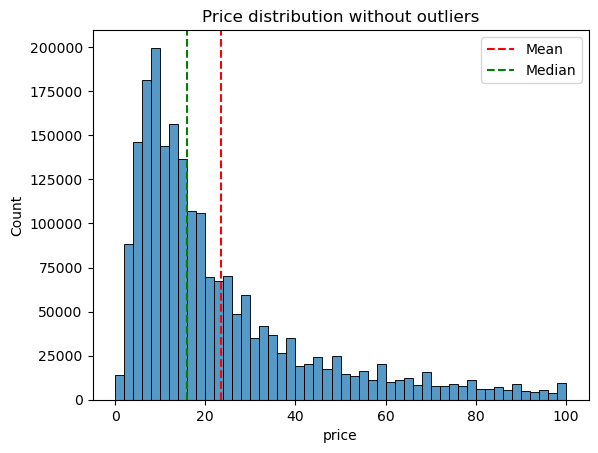

In [23]:
df_no_outliers = df[df['price'] <= Q3 + 1.5 * IQR]

sns.histplot(df_no_outliers['price'], bins=50)
plt.axvline(df_no_outliers['price'].mean(), color="red", linestyle="--", label="Mean")
plt.axvline(df_no_outliers['price'].median(), color="green", linestyle="--", label="Median")
plt.title('Price distribution without outliers')
plt.legend()
plt.show()

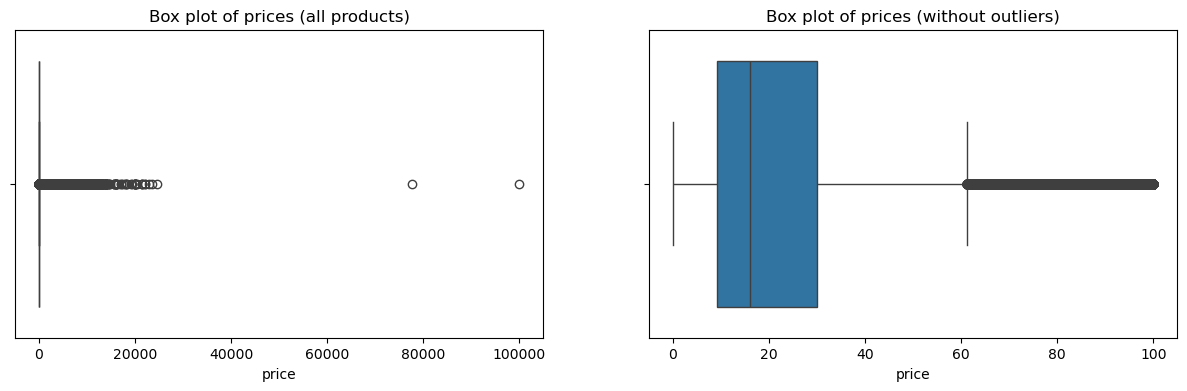

In [24]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 4))

sns.boxplot(x='price', data=df, ax=axs[0])
axs[0].set_title('Box plot of prices (all products)')

sns.boxplot(x='price', data=df_no_outliers, ax=axs[1])
axs[1].set_title('Box plot of prices (without outliers)')

plt.show()

In [25]:
# most expensive products
df.sort_values(by='price', ascending=False)[['title', 'price', 'category']].head(10)

,title,price,category
2008013,HB FBA Test Treadmill,100000.00,Sports & Outdoors
1987238,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,77752.00,Desktop PCs
1905315,Abaodam decor christmas ornaments Desk Ornamen...,24674.59,Garden Storage & Housing
1408966,BM4445-FI1-01200R10-03-E03 Driver,23482.73,Scanners & Accessories
319555,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,22933.42,Projectors
1490285,YXHUI Kids Girls Figure Skating Dress Long Sle...,21999.00,Sports & Outdoors
1490286,YXHUI Kids Girls Figure Skating Dress Long Sle...,21999.00,Sports & Outdoors
1907272,Outdoor Furniture Wood Porch Swing Black Brown...,21464.82,Garden Storage & Housing
1907271,Outdoor Furniture Wood Porch Swing Black Brown...,21464.82,Garden Storage & Housing
1907273,Outdoor Furniture Wood Porch Swing Black Brown...,21464.82,Garden Storage & Housing


**Insights**

- Most products fall into the low price range: half of all products cost less than ~£19 and 75% cost less than ~£46. The distribution is strongly right-skewed, with peaks at prices like £9.99.
- The box plot shows a very large number of outliers (~13% of the products cost more than ~£100), with some products reaching £100,000. These expensive items inflate the mean and the variance.
- For pricing decisions the median is a much better "typical price" than the mean.

### Part 3: Unpacking Product Ratings

The rating is stored in the `stars` column. A rating of **0** means that the product has **no reviews yet** - it is not a real rating, as Amazon ratings go from 1 to 5. Let's check how many products have no rating:

In [26]:
df['stars'].value_counts().head(10)

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
Name: count, dtype: int64

In [27]:
no_rating = df[df['stars'] == 0]
print(f"Products without rating: {len(no_rating)} ({round(len(no_rating) / len(df) * 100, 1)}%)")

Products without rating: 1225641 (50.2%)


About half of all products have no rating. Including them would distort all statistics (the mode and median would be 0), so we analyse the rated products only and compare with all products where useful.

In [28]:
rated = df[df['stars'] > 0]

#### 1. Measures of Centrality

In [29]:
round(float(rated['stars'].mean()), 2)

4.32

In [30]:
round(float(rated['stars'].median()), 2)

4.4

In [31]:
rated['stars'].mode()

0    4.5
Name: stars, dtype: float64

In [32]:
# for comparison: all products including those without rating
print(f"Mean: {round(float(df['stars'].mean()), 2)}, Median: {df['stars'].median()}, Mode: {df['stars'].mode()[0]}")

Mean: 2.15, Median: 0.0, Mode: 0.0


Customers generally rate products very positively: the mean rating of rated products is ~4.3, the median 4.4 and the most common rating 4.5 stars. Including the unrated products would wrongly suggest a median and mode of 0.

#### 2. Measures of Dispersion

In [33]:
round(float(rated['stars'].var()), 2)

0.31

In [34]:
round(float(rated['stars'].std()), 2)

0.56

In [35]:
Q1_stars = rated['stars'].quantile(0.25)
Q3_stars = rated['stars'].quantile(0.75)
IQR_stars = Q3_stars - Q1_stars
print(f"Q1: {Q1_stars}, Q3: {Q3_stars}, IQR: {round(IQR_stars, 2)}")

Q1: 4.1, Q3: 4.6, IQR: 0.5


In [36]:
round(rated['stars'].describe(), 2)

count    1218010.00
mean           4.32
std            0.56
min            1.00
25%            4.10
50%            4.40
75%            4.60
max            5.00
Name: stars, dtype: float64

Among rated products the ratings are quite consistent: the standard deviation is only ~0.56 stars and the middle 50% of the ratings lie between 4.1 and 4.6 (IQR = 0.5). The full range from 1 to 5 is used, but low ratings are rare.

#### 3. Shape of the Distribution

In [37]:
round(float(rated['stars'].skew()), 2)

-2.38

In [38]:
round(float(rated['stars'].kurtosis()), 2)

9.78

- The skewness of about **-2.4** is negative: the distribution is **left-skewed**, with a long tail on the left (towards low ratings) and the bulk of the data on the right (high ratings). As expected, the mean (4.3) is below the median (4.4).
- The kurtosis of about **9.8** (a normal distribution has 0) shows a very peaked distribution with heavy tails: most ratings are concentrated tightly around 4-5 stars, with a few extreme low values.
- So the ratings are **not normally distributed** - they lean strongly towards higher values.

#### 4. Visualizations

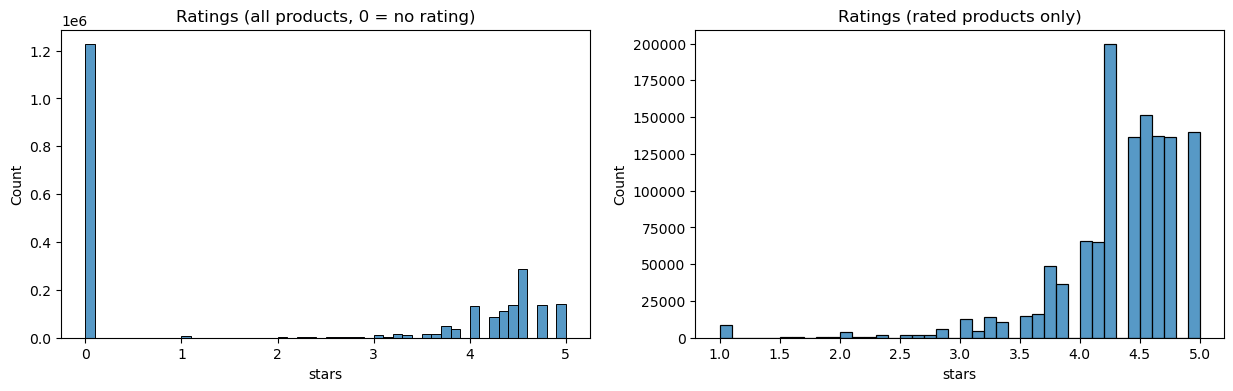

In [39]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 4))

sns.histplot(df['stars'], bins=50, ax=axs[0])
axs[0].set_title('Ratings (all products, 0 = no rating)')

sns.histplot(rated['stars'], bins=40, ax=axs[1])
axs[1].set_title('Ratings (rated products only)')

plt.show()

In [40]:
rated['stars'].value_counts().head(10)

stars
4.5    151577
4.6    136995
4.4    136165
5.0    128492
4.3    112564
4.7     94566
4.2     86871
4.0     66089
4.1     65115
4.8     41858
Name: count, dtype: int64

The most common ratings are 4.5, 4.6 and 4.4 stars, followed by a peak at 5.0. Ratings below 3.5 are rare.

---
## Business Report: Amazon UK Product Insights

**1. Categories**
- The listings are dominated by **Sports & Outdoors**, which makes up ~34% of all 2.4M listings. All other ~295 categories have under 1% each, and the next largest (Beauty, Handmade Clothing, Bath & Body, Birthday Gifts) are nearly tied at ~19k listings.
- *Implication*: Sports & Outdoors is the most crowded category - sellers there face the most competition and need to stand out. The almost identical counts of the other categories suggest the data was collected per category, so listing counts should not be read as true market size.

**2. Pricing**
- The **typical product is cheap**: median price £19.09, most common price £9.99, and half of all products cost between ~£10 and ~£46.
- The mean (£89) is misleading because a long tail of expensive products (~13% above ~£100, up to £100,000) pushes it up.
- *Implication*: the mass market is below £50, with many products at prices like £9.99. New products competing on volume should be priced in that range; premium products are a niche with fewer competitors. Extreme prices should be checked for data errors before they are used for pricing decisions.

**3. Ratings**
- About **50% of the products have no rating** at all - many listings get little or no customer feedback.
- Rated products score high and consistently: mean 4.3, median 4.4, mode 4.5, with the middle 50% between 4.1 and 4.6. The distribution is strongly left-skewed and peaked.
- *Implication*: a rating of ~4.4 is just *average* on Amazon UK, so it doesn't make a product stand out; anything below ~4.1 is in the bottom quarter. Getting the first reviews is an important lever, since half of the products have none.